# Feature Analysis for Forecasting

This notebook analyses the cleaned and aggregated `cohort_state_table.csv` to identify useful forecasting features for student load prediction.

The analysis focuses on two forecasting targets:

- `student_hc`: Headcount
- `actual_eftsl`: Equivalent Full-Time Student Load

The purpose is not to build the final forecasting model yet, but to understand which fields are likely to be useful for:

- Markov-style forecasting
- Linear regression baseline forecasting

## 1. Data Source

The input table is `cohort_state_table.csv`, which was generated from the cleaned Actuals data.

Each row represents an aggregated cohort-state-period record.  
In other words, each row describes:

- which cohort the record belongs to
- which academic period it refers to
- which state the cohort is in
- the aggregated HC and EFTSL values for that group

This table is used as the main input for feature analysis.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "processed" / "cohort_state_table.csv"

df = pd.read_csv(data_path)

df.shape, df.columns.tolist()##导入

((374591, 22),
 ['ACAD_PROG',
  'ACADEMIC_CAREER',
  'FUNDING_GROUP',
  'PROGRAM_COMMENCING_YEAR',
  'PROGRAM_COMMENCING_TERM',
  'ACADEMIC_YEAR',
  'raw_term',
  'term_academic_year',
  'teaching_period_label',
  'calendar_system',
  'term_order',
  'period_delta',
  'period_start_fraction',
  'period_time',
  'term_key',
  'STUDENT_STATUS',
  'TERM_UOC_BAND',
  'state',
  'student_hc',
  'actual_eftsl',
  'source_rows',
  'raw_term_labels'])

In [5]:
df.head()
df[["student_hc", "actual_eftsl"]].describe()
df.isna().sum().sort_values(ascending=False)##检查

ACAD_PROG                  0
ACADEMIC_CAREER            0
source_rows                0
actual_eftsl               0
student_hc                 0
state                      0
TERM_UOC_BAND              0
STUDENT_STATUS             0
term_key                   0
period_time                0
period_start_fraction      0
period_delta               0
term_order                 0
calendar_system            0
teaching_period_label      0
term_academic_year         0
raw_term                   0
ACADEMIC_YEAR              0
PROGRAM_COMMENCING_TERM    0
PROGRAM_COMMENCING_YEAR    0
FUNDING_GROUP              0
raw_term_labels            0
dtype: int64

## 2. Basic Target Distribution

For each target variable:

- `mean` represents the average value per cohort-state-period record.
- `median` represents the middle value and is less affected by extreme values.
- `sum` represents the total contribution to student load.
- `std` represents the standard deviation, which indicates how much values vary within a group.

A high `std` means that the group contains both small and large cohort-state records, so its load is less stable.

In [6]:
cohort_cols = [
    "ACAD_PROG",
    "ACADEMIC_CAREER",
    "FUNDING_GROUP",
    "PROGRAM_COMMENCING_YEAR",
    "PROGRAM_COMMENCING_TERM",
]

time_cols = [
    "term_academic_year",
    "teaching_period_label",
    "calendar_system",
    "term_order",
    "period_time",
    "term_key",
]

state_cols = [
    "STUDENT_STATUS",
    "TERM_UOC_BAND",
    "state",
]

target_cols = [
    "student_hc",
    "actual_eftsl",
]

audit_cols = [
    "source_rows",
    "raw_term_labels",
]

field_groups = pd.DataFrame(
    {
        "field_group": (
            ["cohort"] * len(cohort_cols)
            + ["time"] * len(time_cols)
            + ["state"] * len(state_cols)
            + ["target"] * len(target_cols)
            + ["audit"] * len(audit_cols)
        ),
        "field": cohort_cols + time_cols + state_cols + target_cols + audit_cols,
    }
)

field_groups

,field_group,field
0,cohort,ACAD_PROG
1,cohort,ACADEMIC_CAREER
2,cohort,FUNDING_GROUP
3,cohort,PROGRAM_COMMENCING_YEAR
4,cohort,PROGRAM_COMMENCING_TERM
5,time,term_academic_year
6,time,teaching_period_label
7,time,calendar_system
8,time,term_order
9,time,period_time


## 3. Field Categories
The table contains several types of fields:

- Cohort fields identify the student group.
- Time fields describe the academic period.
- State fields describe the current status and load band.
- Target fields are the values we may forecast.
- Audit fields help trace how the table was created but should not be used directly as forecasting features.

This distinction is important because not every column should be directly used as a model feature.

In [7]:
def group_summary_both(df, col):
    summary = df.groupby(col).agg(
        records=("student_hc", "count"),
        hc_mean=("student_hc", "mean"),
        hc_median=("student_hc", "median"),
        hc_sum=("student_hc", "sum"),
        hc_std=("student_hc", "std"),
        eftsl_mean=("actual_eftsl", "mean"),
        eftsl_median=("actual_eftsl", "median"),
        eftsl_sum=("actual_eftsl", "sum"),
        eftsl_std=("actual_eftsl", "std"),
    )
    return summary.sort_values("hc_sum", ascending=False)

In [8]:
career_summary = group_summary_both(df, "ACADEMIC_CAREER")
career_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
ACADEMIC_CAREER,,,,,,,,,
UGRD,202088,6.758823,2.0,1365877,19.711975,2.411449,0.500,487324.81962,7.509130
PGRD,85951,7.627183,2.0,655564,27.787000,2.138730,0.375,183825.97740,9.569198
RSCH,73098,2.168076,1.0,158482,2.347271,0.655704,0.375,47930.62500,0.861575
NAWD,2822,17.535436,1.0,49485,65.555462,5.704603,0.250,16098.38903,26.695838
PGRO,10632,4.021351,2.0,42755,5.183766,0.506478,0.250,5384.87500,0.649675


### Academic Career

This summary compares student load across different academic career groups.

If HC and EFTSL differ clearly across academic career categories, then `ACADEMIC_CAREER` is likely to be useful as:

- a grouping variable for Markov transition analysis
- a categorical feature for the linear regression baseline

In [9]:
funding_summary = group_summary_both(df, "FUNDING_GROUP")
funding_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
FUNDING_GROUP,,,,,,,,,
DEST,203877,5.794979,2.0,1181463,17.513447,1.952680,0.500,398106.553595,6.566623
INTL,112441,7.175657,2.0,806838,28.347752,2.489478,0.500,279919.356945,10.333611
FEEP,43861,4.532067,2.0,198781,9.385614,0.824461,0.375,36161.671380,2.361355
OTHR,14412,5.903483,1.0,85081,13.227513,1.830218,0.500,26377.104130,5.488505


### Funding Group

Funding group is important because domestic, international, fee-paying, and other funding groups may have different enrolment and continuation patterns.

If the distribution differs across funding groups, this field should be considered in the forecasting design.

In [10]:
status_summary = group_summary_both(df, "STUDENT_STATUS")
status_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
STUDENT_STATUS,,,,,,,,,
Cont,321969,5.667629,2.0,1824801,18.427502,1.814263,0.500,584136.407885,6.617344
NAC,27696,13.169663,3.0,364747,41.259906,4.664745,0.875,129194.775995,15.999325
TransIn,24926,3.314411,1.0,82615,7.534381,1.092574,0.500,27233.502170,2.442753


In [12]:
uoc_summary = group_summary_both(df, "TERM_UOC_BAND")
uoc_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
TERM_UOC_BAND,,,,,,,,,
0-48,122354,7.780064,2.0,951922,26.148494,2.422760,0.500,296434.431005,9.875743
49-96,98379,6.598268,2.0,649131,23.205401,2.223208,0.500,218716.931540,8.204111
97-144,73932,5.172834,2.0,382438,13.357451,1.777211,0.500,131392.746350,5.069045
145-192,51541,3.892687,1.0,200633,10.560960,1.293966,0.500,66692.314710,3.702645
193-240,20826,2.879766,1.0,59974,8.232401,0.927419,0.375,19314.427385,2.891943
241-288,5950,3.952269,1.0,23516,15.613688,1.147764,0.375,6829.194890,4.776306
289-336,1609,2.827222,1.0,4549,9.720854,0.736259,0.250,1184.640170,2.124407


In [13]:
state_summary = group_summary_both(df, "state")
state_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
state,,,,,,,,,
Cont | 49-96,88205,6.836971,2.0,603055,24.153548,2.294354,0.500000,202373.465410,8.547513
Cont | 0-48,87138,6.547993,2.0,570579,20.277551,1.875541,0.375000,163430.916210,7.363250
Cont | 97-144,69765,5.313252,2.0,370679,13.670441,1.820078,0.500000,126977.725255,5.184653
NAC | 0-48,24864,13.982947,3.0,347672,43.069562,4.955083,1.000000,123203.175135,16.734734
Cont | 145-192,49618,3.939961,1.0,195493,10.646273,1.306946,0.500000,64848.054295,3.734435
Cont | 193-240,20054,2.898773,1.0,58132,8.220744,0.936462,0.375000,18779.804545,2.924403
TransIn | 0-48,10352,3.252608,1.0,33671,6.274487,0.946710,0.500000,9800.339660,1.910274
TransIn | 49-96,7684,3.934800,1.0,30235,8.988389,1.411094,0.500000,10842.844330,3.053264
Cont | 241-288,5685,3.978188,1.0,22616,15.453748,1.163242,0.375000,6613.030460,4.810101


In [14]:
period_summary = group_summary_both(df, "teaching_period_label")
period_summary

,records,hc_mean,hc_median,hc_sum,hc_std,eftsl_mean,eftsl_median,eftsl_sum,eftsl_std
teaching_period_label,,,,,,,,,
T1,66578,6.814398,2.0,453689,24.833285,2.065731,0.37500,137532.21879,8.408243
T2,64426,6.516205,2.0,419813,23.654567,1.939482,0.37500,124953.08616,7.609402
T3,66374,6.246512,2.0,414606,22.566323,1.831727,0.37500,121579.01802,7.325316
S1,57087,6.633297,2.0,378675,19.543255,2.761585,0.50025,157650.58433,9.090258
S2,59081,6.299927,2.0,372206,18.818334,2.624492,0.50000,155057.60396,8.649226
U1,24394,3.071698,1.0,74931,10.797757,0.534752,0.25000,13044.74865,1.569309
ADFA Summer Semester,15568,3.554085,1.0,55330,8.798817,0.595632,0.25000,9272.80114,1.697534
ADFA S1,4719,5.875821,2.0,27728,11.451940,1.644204,0.50000,7759.00000,4.146911
ADFA S2,4771,5.471390,2.0,26104,9.560739,1.577355,0.50000,7525.56250,3.814658


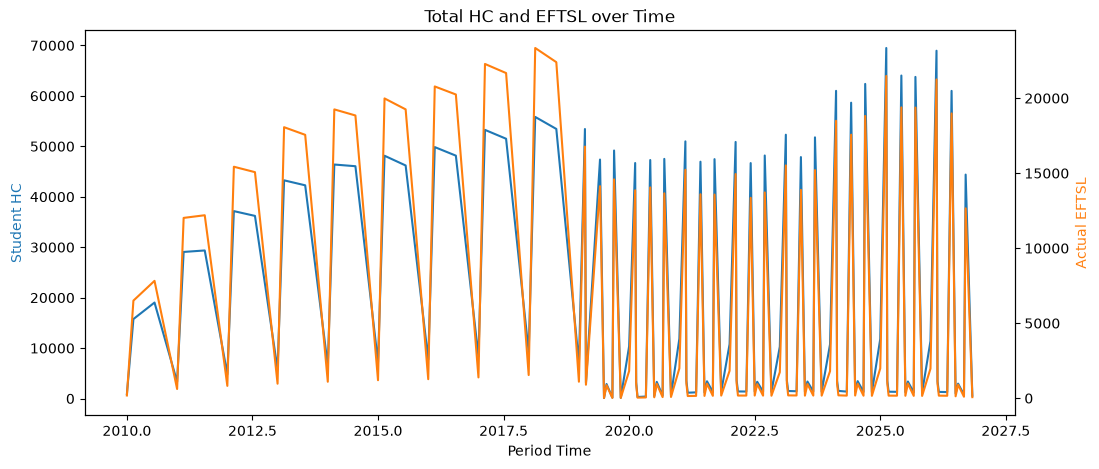

In [15]:
time_summary = (
    df.groupby("period_time")[["student_hc", "actual_eftsl"]]
    .sum()
    .reset_index()
    .sort_values("period_time")
)

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(time_summary["period_time"], time_summary["student_hc"], color="tab:blue")
ax1.set_xlabel("Period Time")
ax1.set_ylabel("Student HC", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(time_summary["period_time"], time_summary["actual_eftsl"], color="tab:orange")
ax2.set_ylabel("Actual EFTSL", color="tab:orange")

plt.title("Total HC and EFTSL over Time")
plt.show()

### Figure 1: Total HC and EFTSL over Time

This chart compares the total `student_hc` and `actual_eftsl` across academic periods.

The two lines are expected to move in a similar direction because HC and EFTSL both measure student load, but they are not identical. HC measures the number of students, while EFTSL reflects study load intensity.

This chart helps identify whether student load has a time trend or visible period-level fluctuations. It also supports the idea that HC-focused forecasting can potentially be extended to EFTSL forecasting, because both targets appear to be related over time.

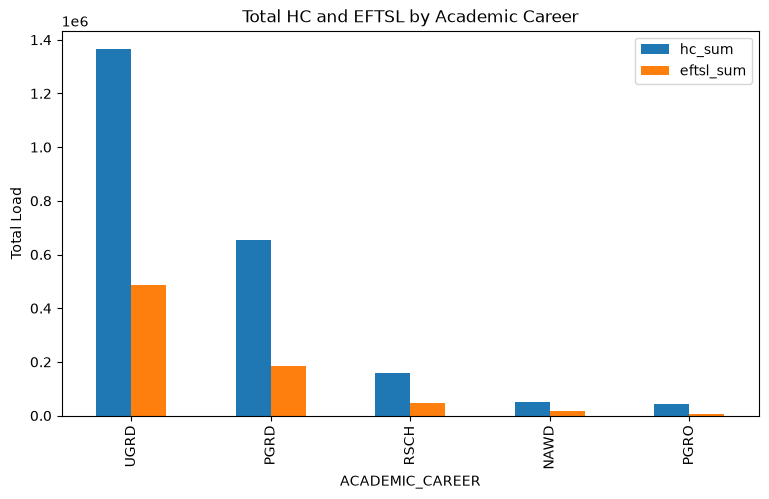

In [16]:
career_summary[["hc_sum", "eftsl_sum"]].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total HC and EFTSL by Academic Career",
)

plt.ylabel("Total Load")
plt.show()

### Figure 2: Total HC and EFTSL by Academic Career

This chart shows that student load is not evenly distributed across academic career groups.

`UGRD` and `PGRD` contribute the largest share of total HC and EFTSL. This suggests that `ACADEMIC_CAREER` is an important cohort-level feature.

For the Markov model, academic career may be useful as a grouping variable when estimating transitions. For the linear regression baseline, it can be used as a categorical feature.

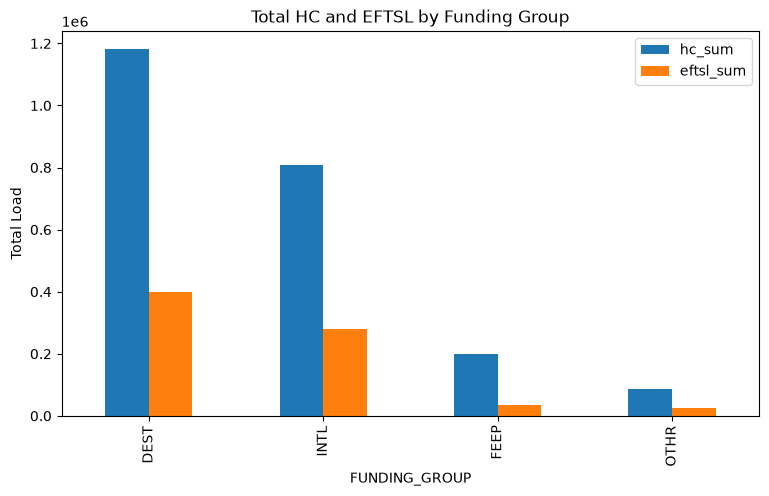

In [17]:
funding_summary[["hc_sum", "eftsl_sum"]].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total HC and EFTSL by Funding Group",
)

plt.ylabel("Total Load")
plt.show()

### Figure 3: Total HC and EFTSL by Funding Group

This chart shows that funding groups have different load contributions.

`DEST` and `INTL` account for most of the total student load. This indicates that `FUNDING_GROUP` is likely to be useful for forecasting, because different funding groups may follow different enrolment and continuation patterns.

This field should be considered both for Markov grouping and for the linear regression baseline.

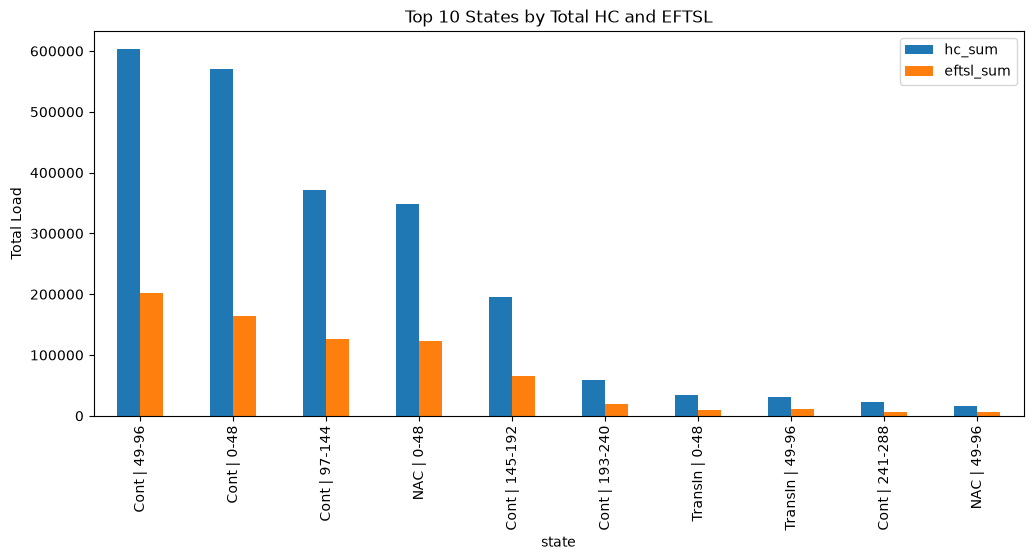

In [18]:
top_states = state_summary.head(10)

top_states[["hc_sum", "eftsl_sum"]].plot(
    kind="bar",
    figsize=(12, 5),
    title="Top 10 States by Total HC and EFTSL",
)

plt.ylabel("Total Load")
plt.show()

### Figure 4: Top 10 States by Total HC and EFTSL

This chart shows which Markov states contribute most to total student load.

The largest states are mainly continuing student states, such as `Cont | 49-96`, `Cont | 0-48`, and `Cont | 97-144`. This suggests that continuing students are a major driver of student load.

The state definition is therefore meaningful for Markov-style forecasting, because it captures both student status and UOC band.

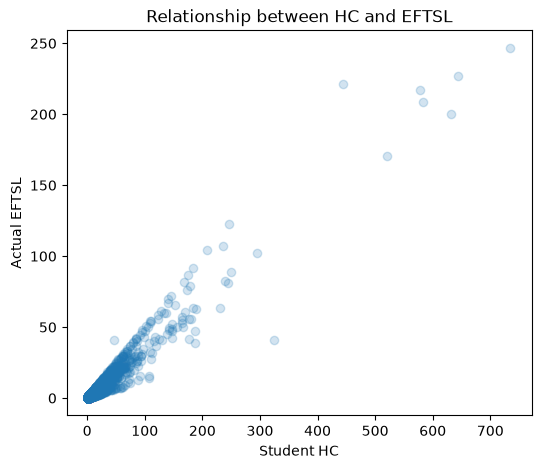

In [19]:
sample = df.sample(min(10000, len(df)), random_state=42)

plt.figure(figsize=(6, 5))
plt.scatter(sample["student_hc"], sample["actual_eftsl"], alpha=0.2)
plt.xlabel("Student HC")
plt.ylabel("Actual EFTSL")
plt.title("Relationship between HC and EFTSL")
plt.show()

### Figure 5: Relationship between HC and EFTSL

This scatter plot shows the relationship between `student_hc` and `actual_eftsl`.

The positive relationship suggests that records with higher HC usually also have higher EFTSL. However, the relationship is not perfectly one-to-one because EFTSL also depends on study load intensity.

This supports analysing both HC and EFTSL as related but distinct forecasting targets.

In [22]:
cohort_period = (
    df.groupby(cohort_cols + [
        "term_key",
        "period_time",
        "term_academic_year",
        "teaching_period_label",
        "calendar_system",
        "term_order",
    ], as_index=False)
    .agg(
        student_hc=("student_hc", "sum"),
        actual_eftsl=("actual_eftsl", "sum"),
        state_count=("state", "nunique"),
        source_rows=("source_rows", "sum"),
    )
    .sort_values(cohort_cols + ["period_time"])
)

cohort_period["previous_student_hc"] = (
    cohort_period.groupby(cohort_cols)["student_hc"].shift(1)
)

cohort_period["previous_actual_eftsl"] = (
    cohort_period.groupby(cohort_cols)["actual_eftsl"].shift(1)
)

cohort_period["hc_change"] = (
    cohort_period["student_hc"] - cohort_period["previous_student_hc"]
)

cohort_period["eftsl_change"] = (
    cohort_period["actual_eftsl"] - cohort_period["previous_actual_eftsl"]
)

cohort_period["cohort_age"] = (
    cohort_period["term_academic_year"] - cohort_period["PROGRAM_COMMENCING_YEAR"]
)

cohort_period[
    [
        "student_hc",
        "previous_student_hc",
        "hc_change",
        "actual_eftsl",
        "previous_actual_eftsl",
        "eftsl_change",
        "cohort_age",
        "state_count",
    ]
].head(10)

,student_hc,previous_student_hc,hc_change,actual_eftsl,previous_actual_eftsl,eftsl_change,cohort_age,state_count
0,1,NaN,NaN,0.5,NaN,NaN,0,1
1,1,NaN,NaN,0.5,NaN,NaN,0,1
2,1,NaN,NaN,0.5,NaN,NaN,0,1
3,1,NaN,NaN,0.5,NaN,NaN,0,1
4,1,NaN,NaN,0.5,NaN,NaN,0,1
5,1,NaN,NaN,0.5,NaN,NaN,0,1
6,1,1.0,0.0,0.5,0.5,0.0,0,1
7,1,NaN,NaN,0.5,NaN,NaN,0,1
8,1,NaN,NaN,0.5,NaN,NaN,0,1
9,3,NaN,NaN,1.5,NaN,NaN,0,1


In [23]:
lagged_periods = cohort_period.dropna(
    subset=["previous_student_hc", "previous_actual_eftsl"]
)

numeric_features = [
    "previous_student_hc",
    "previous_actual_eftsl",
    "hc_change",
    "eftsl_change",
    "cohort_age",
    "term_order",
    "state_count",
]

correlation_table = lagged_periods[
    numeric_features + ["student_hc", "actual_eftsl"]
].corr()

correlation_table

,previous_student_hc,previous_actual_eftsl,hc_change,eftsl_change,cohort_age,term_order,state_count,student_hc,actual_eftsl
previous_student_hc,1.000000,0.969586,-0.551663,-0.521001,-0.124738,-0.028042,0.339202,0.730943,0.674066
previous_actual_eftsl,0.969586,1.000000,-0.570859,-0.587041,-0.121590,-0.043241,0.331884,0.679277,0.648480
hc_change,-0.551663,-0.570859,1.000000,0.958127,0.023738,0.084635,0.049703,0.165966,0.215630
eftsl_change,-0.521001,-0.587041,0.958127,1.000000,0.018703,0.089240,0.045527,0.167957,0.235577
cohort_age,-0.124738,-0.121590,0.023738,0.018703,1.000000,-0.161310,-0.084882,-0.128057,-0.128380
term_order,-0.028042,-0.043241,0.084635,0.089240,-0.161310,1.000000,0.027269,0.036095,0.032002
state_count,0.339202,0.331884,0.049703,0.045527,-0.084882,0.027269,1.000000,0.441711,0.441228
student_hc,0.730943,0.679277,0.165966,0.167957,-0.128057,0.036095,0.441711,1.000000,0.973389
actual_eftsl,0.674066,0.648480,0.215630,0.235577,-0.128380,0.032002,0.441228,0.973389,1.000000


The first observed period for each cohort does not have a previous period, so lag features such as `previous_student_hc` and `previous_actual_eftsl` are missing for those rows.

This is expected behaviour rather than an error. For correlation analysis involving lag features, only rows with available previous-period values are used.

# Conclution
Although the Markov model mainly relies on the state field, the feature analysis is still necessary because cohort construction and feature analysis answer different questions. Cohort construction defines the modelling unit: which group of students is being observed, in which period, in which state, and with what HC/EFTSL value. Feature analysis then checks whether these fields actually reveal useful forecasting patterns. In this project, the analysis confirms that state is meaningful for Markov-style transition modelling, while fields such as ACADEMIC_CAREER, FUNDING_GROUP, calendar_system, and teaching_period_label may help decide whether transitions should be estimated separately for different groups. For the linear regression baseline, lag, cohort, and time-related features are also useful candidate predictors. Therefore, feature analysis does not replace cohort construction; it validates and interprets the modelling table before forecasting.
虽然马尔可夫模型主要依赖 state 字段，但特征分析仍然是必要的，因为 cohort 构建和特征分析回答的是不同问题。Cohort 构建解决的是“建模单位是什么”：我们在观察哪一类学生、处于哪个时间点、属于什么状态，以及对应多少 HC/EFTSL。特征分析解决的是“这些字段是否真的呈现出有用的预测规律”。在本项目中，特征分析确认了 state 对 Markov 状态转移建模是有意义的，同时 ACADEMIC_CAREER、FUNDING_GROUP、calendar_system、teaching_period_label 等字段可以帮助判断是否需要对不同群体分别估计转移规律。对于线性回归 baseline，上一期负荷、cohort 年龄和时间相关字段也可能是有用预测特征。因此，特征分析不是重复 cohort 构建，而是在预测前验证和解释这张建模表。